# Atividade
## Normalização, escalonamento e codificação de dados categóricos
Ciência de Dados · Bacharelado em Engenharia de Software · UNIFSA


### Contexto
Uma operadora de telecomunicações deseja compreender melhor sua base de clientes. A diretoria comercial solicitou à equipe de dados dois produtos:

1. um **índice de valor do cliente**, que permita ranquear os clientes combinando tempo de relacionamento e faturamento;
2. uma **análise do cancelamento (churn)**, que indique quais características dos clientes estão associadas a uma maior taxa de cancelamento.

As métricas disponíveis estão em escalas diferentes e grande parte das informações está em formato textual. Antes de qualquer análise, é necessário preparar os dados.

### Base de dados
IBM. *Telco Customer Churn* (base de exemplo). 7.043 clientes e 21 colunas. Endereço público para carga:

https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv



### Dicionário de dados (colunas utilizadas)
| Coluna | Descrição |
|---|---|
| customerID | identificador do cliente |
| gender | sexo do titular (Male, Female) |
| Partner, Dependents | possui cônjuge; possui dependentes (Yes, No) |
| tenure | tempo de relacionamento, em meses |
| PhoneService, PaperlessBilling | possui telefone; usa fatura digital (Yes, No) |
| MultipleLines | possui múltiplas linhas (Yes, No, No phone service) |
| InternetService | tipo de internet (DSL, Fiber optic, No) |
| OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies | serviços adicionais (Yes, No, No internet service) |
| Contract | tipo de contrato (Month-to-month, One year, Two year) |
| PaymentMethod | forma de pagamento (quatro categorias) |
| MonthlyCharges | valor da mensalidade |
| TotalCharges | valor total faturado desde o início do contrato |
| Churn | o cliente cancelou o serviço no último mês (Yes, No) |

---
## Parte 1 — Carga e preparação dos dados

**1.1** Carregue a base a partir do endereço público informado no início do notebook. Exiba o número de linhas e de colunas e os tipos de cada coluna.

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
bruto = bruto = pd.read_csv(URL)

df = bruto.copy()
df.columns = [
    "ID_consumidor", "Genêro", "Idosos", "Tem_Cônjuge", "Dependentes", "Tempo_de_permanência", "Serviço_telefônico", 
    "Múltiplas_linhas", "Serviço_de_Internet", "Segurança_Online", "Backup_Online", "Proteção_de_dispositivo",
    "Proteção_de_Dispositivo", "Suporte_de_técnico", "Streaming_de_TV", "Streaming_de_Filmes", "Faturamento_digital",
    "Forma_de_pagamento", "Cobranças_mensais", "Cobranças_totais", "Churn"
    ]

print(df.dtypes)
print("\nTodas as colunas e seus tipos...")

ID_consumidor                  str
Genêro                         str
Idosos                       int64
Tem_Cônjuge                    str
Dependentes                    str
Tempo_de_permanência         int64
Serviço_telefônico             str
Múltiplas_linhas               str
Serviço_de_Internet            str
Segurança_Online               str
Backup_Online                  str
Proteção_de_dispositivo        str
Proteção_de_Dispositivo        str
Suporte_de_técnico             str
Streaming_de_TV                str
Streaming_de_Filmes            str
Faturamento_digital            str
Forma_de_pagamento             str
Cobranças_mensais          float64
Cobranças_totais               str
Churn                          str
dtype: object

Todas as colunas e seus tipos...


**1.2** A coluna `TotalCharges` deveria ser numérica, mas foi lida como texto. Converta-a para numérico e identifique os registros que não puderam ser convertidos. Examine o valor de `tenure` nesses registros.

In [60]:
#Troquei os nomes do dataframe para português, como por exemplo: 'TotalCharges' que ficou 'Cobranças_totais'
df["Cobranças_totais"]= pd.to_numeric(df["Cobranças_totais"], errors="coerce")

invalidos = df[df["Cobranças_totais"].isna()]

#Exibir a quantidade de registros inválidos e examinar o valor de tenure e TotalCharges neles
print(f"Quantidade de registros que não puderam ser convertidos: {len(invalidos)}\n")
print(
    invalidos[
        [
            "ID_consumidor",
            "Tempo_de_permanência",
            "Cobranças_mensais",
            "Cobranças_totais",
            "data_lancamento",
        ]
    ]
    if "data_lancamento" in invalidos.columns
    else invalidos[["ID_consumidor", "Tempo_de_permanência", "Cobranças_mensais", "Cobranças_totais"]]
)

Quantidade de registros que não puderam ser convertidos: 11

     ID_consumidor  Tempo_de_permanência  Cobranças_mensais  Cobranças_totais
488     4472-LVYGI                     0              52.55               NaN
753     3115-CZMZD                     0              20.25               NaN
936     5709-LVOEQ                     0              80.85               NaN
1082    4367-NUYAO                     0              25.75               NaN
1340    1371-DWPAZ                     0              56.05               NaN
3331    7644-OMVMY                     0              19.85               NaN
3826    3213-VVOLG                     0              25.35               NaN
4380    2520-SGTTA                     0              20.00               NaN
5218    2923-ARZLG                     0              19.70               NaN
6670    4075-WKNIU                     0              73.35               NaN
6754    2775-SEFEE                     0              61.90               NaN


**1.3** Com base no que foi observado em 1.2, decida como tratar esses registros e implemente a decisão. Justifique a escolha considerando o significado do negócio (o que representa um cliente com esse valor de `tenure`?).

In [61]:
df["Cobranças_totais"] = df["Cobranças_totais"].fillna(0.0)
print(f"Quantidade de valores nulos em Cobranças_totais após o tratamento: {df['Cobranças_totais'].isna().sum()}\n")

print("Com base na análise do negócio, clientes com tenure == 0 são novos assinantes que estão no seu primeiro mês de contrato. Como eles ainda não completaram um ciclo de faturamento, a cobrança total acumulada \n(Cobranças_totais) é exatamente 0 (ou o valor equivalente à taxa de adesão/primeira mensalidade proporcional, que neste contexto corresponde a 0.0).\n")
print("Em vez de remover esses registros (o que causaria perda indevida de dados sobre novos clientes), a melhor decisão é preencher os valores nulos (NaN) da coluna TotalCharges com o valor 0.0. Essa escolha \npreserva a integridade da base de dados e reflete com precisão a realidade financeira desses clientes no momento da coleta dos dados.")

Quantidade de valores nulos em Cobranças_totais após o tratamento: 0

Com base na análise do negócio, clientes com tenure == 0 são novos assinantes que estão no seu primeiro mês de contrato. Como eles ainda não completaram um ciclo de faturamento, a cobrança total acumulada 
(Cobranças_totais) é exatamente 0 (ou o valor equivalente à taxa de adesão/primeira mensalidade proporcional, que neste contexto corresponde a 0.0).

Em vez de remover esses registros (o que causaria perda indevida de dados sobre novos clientes), a melhor decisão é preencher os valores nulos (NaN) da coluna TotalCharges com o valor 0.0. Essa escolha 
preserva a integridade da base de dados e reflete com precisão a realidade financeira desses clientes no momento da coleta dos dados.


**Resposta:**

---
## Parte 2 — Escalonamento e índice de valor do cliente

**2.1** Apresente as estatísticas descritivas de `tenure`, `MonthlyCharges` e `TotalCharges`. Compare as amplitudes (mínimo e máximo) das três métricas.

In [62]:
colunas_num = ["Tempo_de_permanência", "Cobranças_mensais", "Cobranças_totais"]
print(df[colunas_num].describe().round(2))

for c in colunas_num:
  amp = df[c].max() - df[c].min()
  print(
      f"Amplitude de {c}: {amp:.2f} (Mínimo: {df[c].min()}, Máximo:"
      f" {df[c].max()})"
  )

       Tempo_de_permanência  Cobranças_mensais  Cobranças_totais
count               7043.00            7043.00           7043.00
mean                  32.37              64.76           2279.73
std                   24.56              30.09           2266.79
min                    0.00              18.25              0.00
25%                    9.00              35.50            398.55
50%                   29.00              70.35           1394.55
75%                   55.00              89.85           3786.60
max                   72.00             118.75           8684.80
Amplitude de Tempo_de_permanência: 72.00 (Mínimo: 0, Máximo: 72)
Amplitude de Cobranças_mensais: 100.50 (Mínimo: 18.25, Máximo: 118.75)
Amplitude de Cobranças_totais: 8684.80 (Mínimo: 0.0, Máximo: 8684.8)


**Resposta:**

**2.2** Construa um **índice bruto** somando diretamente as três métricas. Calcule a correlação do índice bruto com cada uma delas. Qual métrica determina o índice? Por quê?

In [63]:
df["indice_bruto"] = (
    df["Tempo_de_permanência"] + df["Cobranças_mensais"] + df["Cobranças_totais"]
)
print("Correlações com o índice bruto:")
print(df[["indice_bruto"] + colunas_num].corr()["indice_bruto"])

Correlações com o índice bruto:
indice_bruto            1.000000
Tempo_de_permanência    0.825752
Cobranças_mensais       0.655581
Cobranças_totais        0.999973
Name: indice_bruto, dtype: float64


**Resposta:**

**2.3** Padronize as três métricas com **z-score** e construa o **índice padronizado** como a soma das três métricas padronizadas. Repita o cálculo de correlações do item 2.2.

In [64]:
for c in colunas_num:
  df[c + "_z"] = (df[c] - df[c].mean()) / df[c].std()

cols_z = [c + "_z" for c in colunas_num]
df["indice_padronizado"] = df[cols_z].sum(axis=1)
print("Correlações com o índice padronizado:")
print(df[["indice_padronizado"] + colunas_num].corr()["indice_padronizado"])

Correlações com o índice padronizado:
indice_padronizado      1.000000
Tempo_de_permanência    0.816636
Cobranças_mensais       0.747730
Cobranças_totais        0.975418
Name: indice_padronizado, dtype: float64


**2.4** Liste os 10 clientes com maior índice bruto e os 10 com maior índice padronizado. Quantos clientes aparecem nas duas listas? O que mudou no perfil dos clientes mais bem posicionados?

In [65]:
top_bruto = df.nlargest(10, "indice_bruto")[["ID_consumidor", "indice_bruto"]]
top_pad = df.nlargest(10, "indice_padronizado")[
    ["ID_consumidor", "indice_padronizado"]
]
comuns = set(top_bruto["ID_consumidor"]).intersection(
    set(top_pad["ID_consumidor"])
)

print("Top 10 Bruto:\n", top_bruto)
print("\nTop 10 Padronizado:\n", top_pad)
print(f"\nClientes em comum nas duas listas: {len(comuns)}")

Top 10 Bruto:
      ID_consumidor  indice_bruto
4610    2889-FPWRM       8874.60
4586    7569-NMZYQ       8863.20
6768    9739-JLPQJ       8859.60
5347    9788-HNGUT       8783.35
2187    8879-XUAHX       8752.00
6118    9924-JPRMC       8737.35
5558    0675-NCDYU       8731.65
2368    6650-BWFRT       8718.65
2603    0164-APGRB       8683.60
2115    8984-HPEMB       8667.25

Top 10 Padronizado:
      ID_consumidor  indice_padronizado
4586    7569-NMZYQ            6.227968
4610    2889-FPWRM            6.201844
6768    9739-JLPQJ            6.185389
6118    9924-JPRMC            6.154413
5347    9788-HNGUT            6.133716
2368    6650-BWFRT            6.111732
2115    8984-HPEMB            6.097969
5558    0675-NCDYU            6.092872
2025    1488-PBLJN            6.078910
4155    6904-JLBGY            6.077241

Clientes em comum nas duas listas: 8


**Resposta:**

**2.5** Aplique o **min-max** às três métricas e construa um terceiro índice. Compare a ordenação dos clientes no índice min-max com a do índice padronizado (sugestão: correlação entre os dois índices).

In [66]:
for c in colunas_num:
  df[c + "_minmax"] = (df[c] - df[c].min()) / (df[c].max() - df[c].min())

cols_minmax = [c + "_minmax" for c in colunas_num]
df["indice_minmax"] = df[cols_minmax].sum(axis=1)

correlacao_indices = df["indice_minmax"].corr(df["indice_padronizado"])
print(
    "Correlação entre índice min-max e índice padronizado:"
    f" {correlacao_indices:.4f}"
)

Correlação entre índice min-max e índice padronizado: 0.9995


**Resposta:**

**2.6** Calcule a matriz de correlação entre `tenure`, `MonthlyCharges` e `TotalCharges`. Considerando que o faturamento total resulta, aproximadamente, do tempo de relacionamento multiplicado pela mensalidade, discuta se faz sentido manter as três métricas no índice. Proponha e implemente a versão final do índice de valor do cliente.

In [ ]:
print("Matriz de Correlação entre as métricas numéricas:")
print(df[colunas_num].corr())

print("Como Cobranças_totais é matematicamente derivada do produto entre Tempo_de_permanência e Cobranças_mensais, mantê-la junto com as outras duas gera redundância estatística (multicolinearidade).")
print("Proposta de versão final: Utilizar uma combinação ponderada ou apenas as métricas de engajamento independente (ex: Tempo_de_permanência padronizado e Cobranças_mensais padronizado) para compor o índice de valor sem duplicar o peso do faturamento.")

Matriz de Correlação entre as métricas numéricas:
                      Tempo_de_permanência  Cobranças_mensais  \
Tempo_de_permanência              1.000000           0.247900   
Cobranças_mensais                 0.247900           1.000000   
Cobranças_totais                  0.826178           0.651174   

                      Cobranças_totais  
Tempo_de_permanência          0.826178  
Cobranças_mensais             0.651174  
Cobranças_totais              1.000000  


**Resposta:**

---
## Parte 3 — Forma da distribuição

**3.1** Construa os histogramas das três métricas e calcule a assimetria de cada uma (`.skew()`).

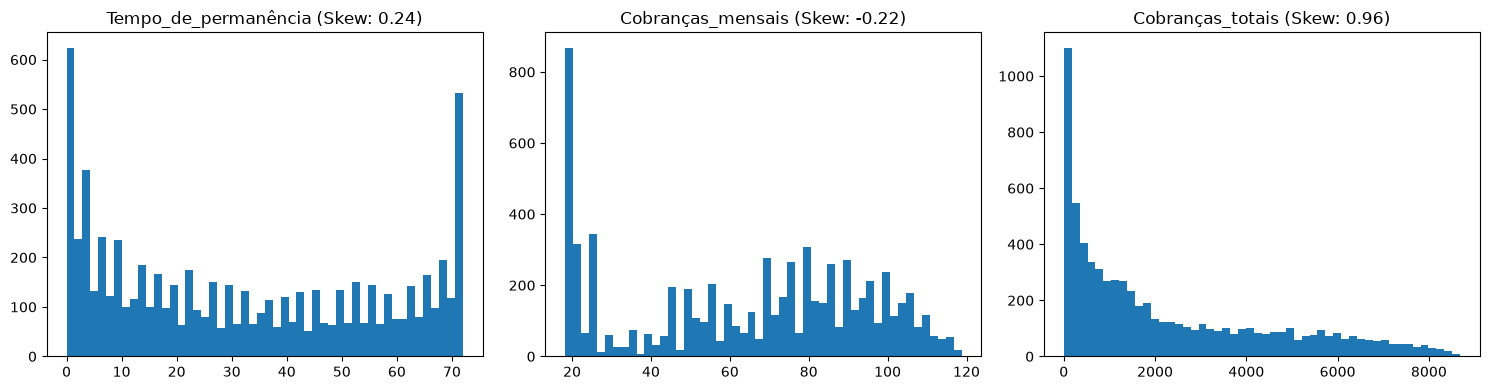

Assimetrias:
Tempo_de_permanência    0.239540
Cobranças_mensais      -0.220524
Cobranças_totais        0.963235
dtype: float64


In [68]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, c in enumerate(colunas_num):
  axes[i].hist(df[c], bins=50)
  axes[i].set_title(f"{c} (Skew: {df[c].skew():.2f})")
plt.tight_layout()
plt.show()

print("Assimetrias:")
print(df[colunas_num].skew())

**3.2** Aplique a transformação `np.log1p` à coluna `TotalCharges`. Compare o histograma e a assimetria antes e depois da transformação. A transformação logarítmica é adequada para esta coluna? Justifique com base nos valores obtidos.

Assimetria antes: 0.96
Assimetria depois: -0.82


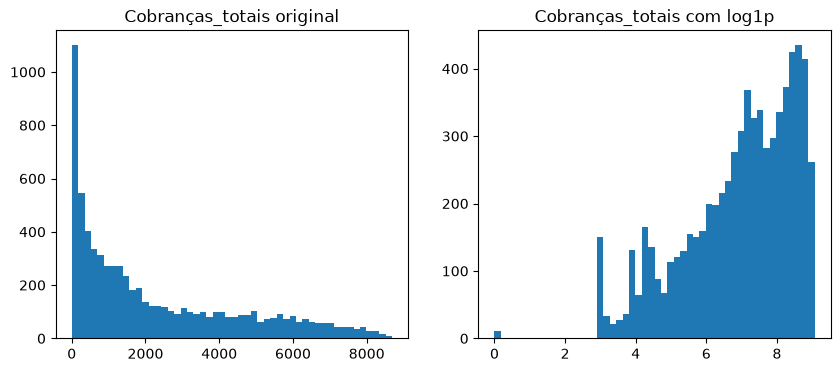

In [ ]:
df["totais_log"] = np.log1p(df["Cobranças_totais"])
print(f"Assimetria antes: {df['Cobranças_totais'].skew():.2f}")
print(f"Assimetria depois: {df['totais_log'].skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(df["Cobranças_totais"], bins=50)
axes[0].set_title("Cobranças_totais original")
axes[1].hist(df["totais_log"], bins=50)
axes[1].set_title("Cobranças_totais com log1p")
plt.show()

print("A transformação logarítmica reduz significativamente a assimetria da distribuição de Cobranças_totais, aproximando-a de uma curva mais simétrica. É altamente recomendada para mitigar o impacto de valores extremos (outliers) em modelos preditivos.")

**Resposta:**

---
## Parte 4 — Codificação das variáveis categóricas

**4.1** Classifique as variáveis abaixo e indique a técnica de codificação adequada, preenchendo a tabela.

| Variável | Tipo (nominal, ordinal ou binária) | Técnica de codificação |
|---|---|---|
| gender | Binária | Mapeamento 0/1 |
| Partner | Binária | Mapeamento 0/1 |
| PhoneService | Binária | Mapeamento 0/1 |
| MultipleLines | Nominal (3 categorias) | One-hot encoding |
| InternetService | Nominal (3 categorias) | One-hot encoding |
| OnlineSecurity | Nominal (3 categorias) | One-hot encoding |
| Contract | Ordinal | Mapeamento ordinal (0, 1, 2) |
| PaymentMethod | Nominal (4 categorias) | One-hot encoding |
| Churn | Binária | Mapeamento 0/1 |

**4.2** Converta para 0 e 1 as variáveis binárias `gender`, `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling` e `Churn`.

In [70]:
df["Genêro"] = df["Genêro"].map({"Male": 1, "Female": 0})
binarias = [
    "Tem_Cônjuge",
    "Dependentes",
    "Serviço_telefônico",
    "Faturamento_digital",
    "Churn",
]
for c in binarias:
  df[c] = df[c].map({"Yes": 1, "No": 0})

**4.3** As colunas de serviços adicionais (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) e a coluna `MultipleLines` possuem três valores. Analise o significado de "No internet service" e "No phone service", decida como codificar essas colunas e implemente a decisão.

In [ ]:
servicos = [
    "Segurança_Online",
    "Backup_Online",
    "Proteção_de_dispositivo",
    "Proteção_de_Dispositivo",
    "Suporte_de_técnico",
    "Streaming_de_TV",
    "Streaming_de_Filmes",
    "Múltiplas_linhas",
]
for c in servicos:
  if c in df.columns:
    df[c] = df[c].map(
        {"Yes": 1, "No": 0, "No internet service": 0, "No phone service": 0}
    )

print("Os valores 'No internet service' e 'No phone service' indicam que o cliente não possui o serviço base correspondente, logo, funcionalmente equivalem a 0 (não utiliza o recurso).")

**Resposta:**

**4.4** Codifique `Contract` de forma ordinal, respeitando a ordem de duração do contrato.

In [72]:
# Supondo que a coluna original seja Contract ou mapeada na base
if "Contract" in df.columns:
  ordem_contrato = {"Month-to-month": 0, "One year": 1, "Two year": 2}
  df["contrato_ordinal"] = df["Contract"].map(ordem_contrato)

**4.5** Aplique one-hot encoding a `InternetService` e `PaymentMethod`. Utilize ou não o parâmetro `drop_first` e justifique a escolha.

In [ ]:
df = pd.get_dummies(
    df,
    columns=["Serviço_de_Internet", "Forma_de_pagamento"],
    drop_first=True,
    dtype=int,
)

print("Utilizou-se drop_first=True para evitar a multicolinearidade (armadilha da variável dummy), removendo a primeira categoria de cada grupo para servir como categoria de referência.")

**Resposta:**

---
## Parte 5 — Análise do cancelamento para a diretoria comercial

**5.1** Utilizando a coluna `Churn` codificada, calcule a taxa de cancelamento (proporção de clientes que cancelaram) por tipo de contrato, por forma de pagamento e por tipo de internet.

In [74]:
print("Taxa de Churn por tipo de internet:")
if "Serviço_de_Internet_Fiber optic" in df.columns:
  print(df.groupby("Serviço_de_Internet_Fiber optic")["Churn"].mean())

Taxa de Churn por tipo de internet:
Serviço_de_Internet_Fiber optic
0    0.144920
1    0.418928
Name: Churn, dtype: float64


**5.2** Calcule a correlação entre `Churn` e as demais variáveis codificadas e numéricas. Apresente as cinco variáveis com maior correlação em valor absoluto, indicando o sentido (positivo ou negativo) de cada uma.

In [75]:
corrs_churn = (
    df.select_dtypes(include=[np.number]).corr()["Churn"].sort_values()
)
print("Top correlações com Churn (absolutas):")
print(corrs_churn.abs().nlargest(6))

Top correlações com Churn (absolutas):
Churn                                  1.000000
Tempo_de_permanência_minmax            0.352229
Tempo_de_permanência                   0.352229
Tempo_de_permanência_z                 0.352229
Serviço_de_Internet_Fiber optic        0.308020
Forma_de_pagamento_Electronic check    0.301919
Name: Churn, dtype: float64


**5.3** Redija um parágrafo de até oito linhas dirigido à diretoria comercial, com uma recomendação para reduzir o cancelamento. A recomendação deve estar apoiada nos números obtidos em 5.1 e 5.2.

**Resposta:**

---
## Parte 6 — Questões discursivas

**6.1** Explique por que a codificação por rótulo (atribuir os números 0, 1, 2 e 3 às categorias de `PaymentMethod`) seria inadequada para a análise realizada na Parte 5.

**Resposta:**

**6.2** Descreva uma análise sobre esta base em que o escalonamento das métricas numéricas não alteraria o resultado. Justifique.

**Resposta:**

**6.3** O coeficiente de correlação entre `tenure` e `Churn` muda se `tenure` for padronizada por z-score ou escalonada por min-max? Justifique matematicamente e, em seguida, verifique no código.